# Spark inference benchmark
Chọn kernel .conda-py311. Notebook chạy các JVM local trong tiến trình riêng, sử dụng model và full test snapshot đã lưu. Mỗi lần chạy ghi vào thư mục mới.


In [1]:
from datetime import datetime
from pathlib import Path
import subprocess
import sys

cwd = Path.cwd().resolve()
root = next(p for p in (cwd, *cwd.parents) if (p / "src" / "benchmarking.py").is_file())
run = root / "outputs" / "benchmark" / datetime.now().strftime("%Y%m%d_%H%M%S_%f")
log = run.with_suffix(".log")
log.parent.mkdir(parents=True, exist_ok=True)
with log.open("xb") as stream:
    subprocess.run([sys.executable, "-X", "utf8", "-u", "-m", "src.benchmarking",
                    "--output", str(run), "--core-comparison"],
                   cwd=root, stdout=stream, stderr=subprocess.STDOUT, check=True)
print(run, log)


D:\network-anomaly-hybrid-vscode\outputs\benchmark\20261113_183307_603161 D:\network-anomaly-hybrid-vscode\outputs\benchmark\20261113_183307_603161.log


,master,rows,read_seconds_mean,read_seconds_std,read_flows_per_second_mean,read_flows_per_second_std,preprocessing_seconds_mean,preprocessing_seconds_std,preprocessing_flows_per_second_mean,preprocessing_flows_per_second_std,...,write_flows_per_second_std,end_to_end_seconds_mean,end_to_end_seconds_std,end_to_end_flows_per_second_mean,end_to_end_flows_per_second_std,repeats,read_partitions,scoring_partitions,spark_slots,driver_memory
0,local[*],100000,3.743516,2.021799,32263.798360,16087.755617,10.120685,1.464088,10032.769008,1576.791700,...,91856.534879,22.439310,3.918312,4550.616648,812.796403,3,7,7,32,4g
1,local[*],500000,3.915344,0.456825,128820.994949,14394.797209,10.557431,1.000052,47655.531516,4683.792074,...,128374.630970,29.087739,1.425580,17217.223570,852.688860,3,16,16,32,4g
2,local[*],1000000,8.092810,5.867864,164116.123006,83892.046499,15.293548,7.419944,74529.196995,28271.852335,...,471500.922976,48.860540,13.207828,21369.594476,5014.546208,3,30,30,32,4g
3,local[*],4653501,16.249848,10.234591,357841.144798,172856.827091,25.283388,7.004352,193121.540851,49537.775776,...,114093.319048,153.384200,15.496673,30549.697493,3135.371115,3,139,139,32,4g
4,local[1],100000,10.933420,8.987275,15978.740515,14144.536607,33.328338,21.832610,5363.212023,5473.374751,...,15908.809108,65.273371,32.874365,1936.215880,1235.284193,3,7,7,1,4g
5,local[2],100000,12.355341,6.039401,9444.783468,4293.906438,38.695224,2.609203,2591.863758,168.300902,...,23299.680372,66.369746,9.729219,1527.024233,207.990504,3,7,7,2,4g
6,local[4],100000,11.136127,9.350231,22132.663675,26271.149680,30.588111,17.863204,4945.597937,4318.597999,...,134221.898301,52.139853,29.120376,2633.803094,1974.328257,3,7,7,4,4g


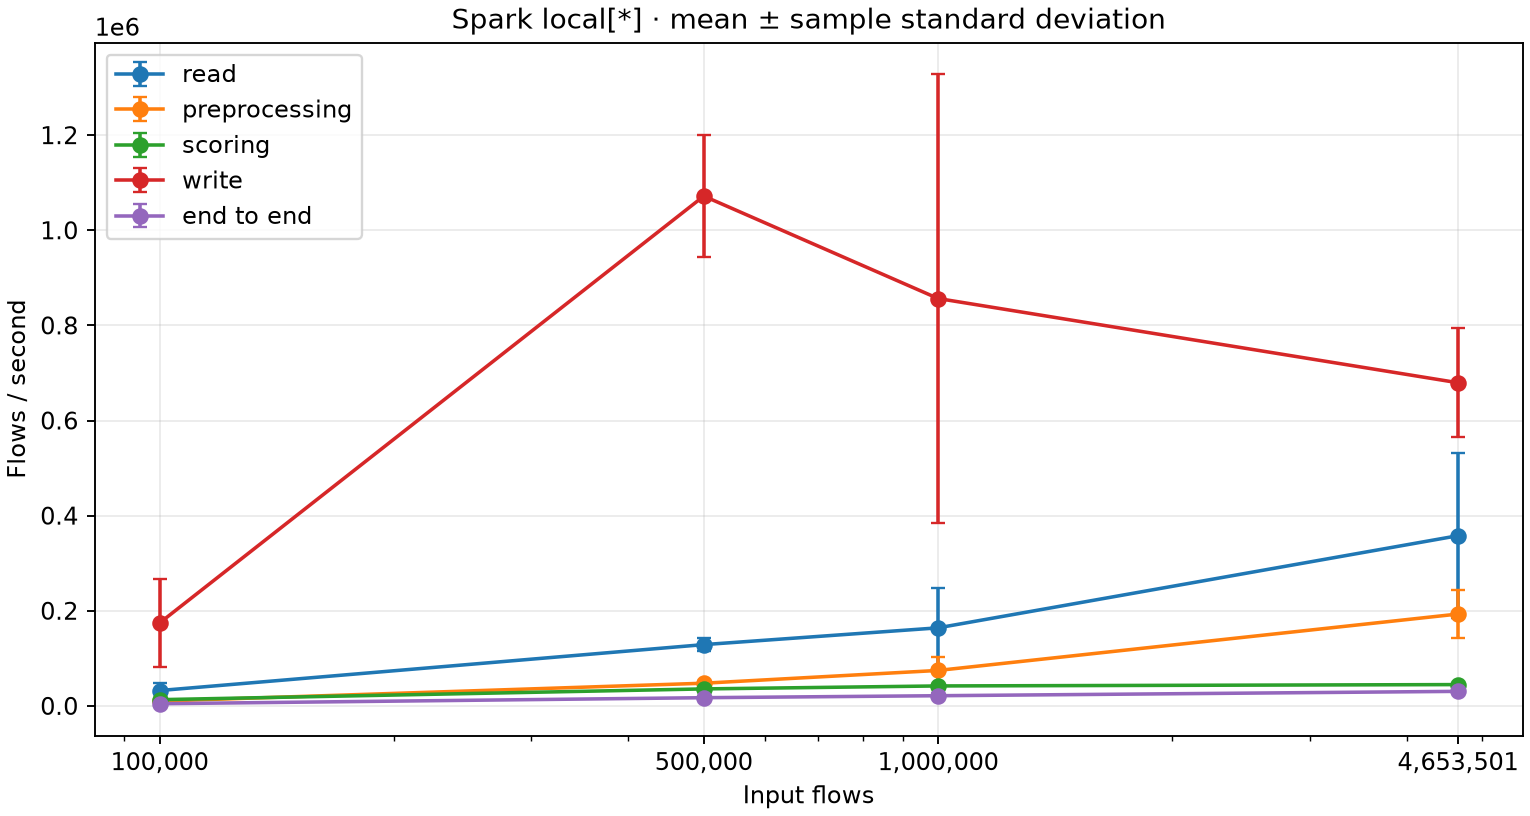

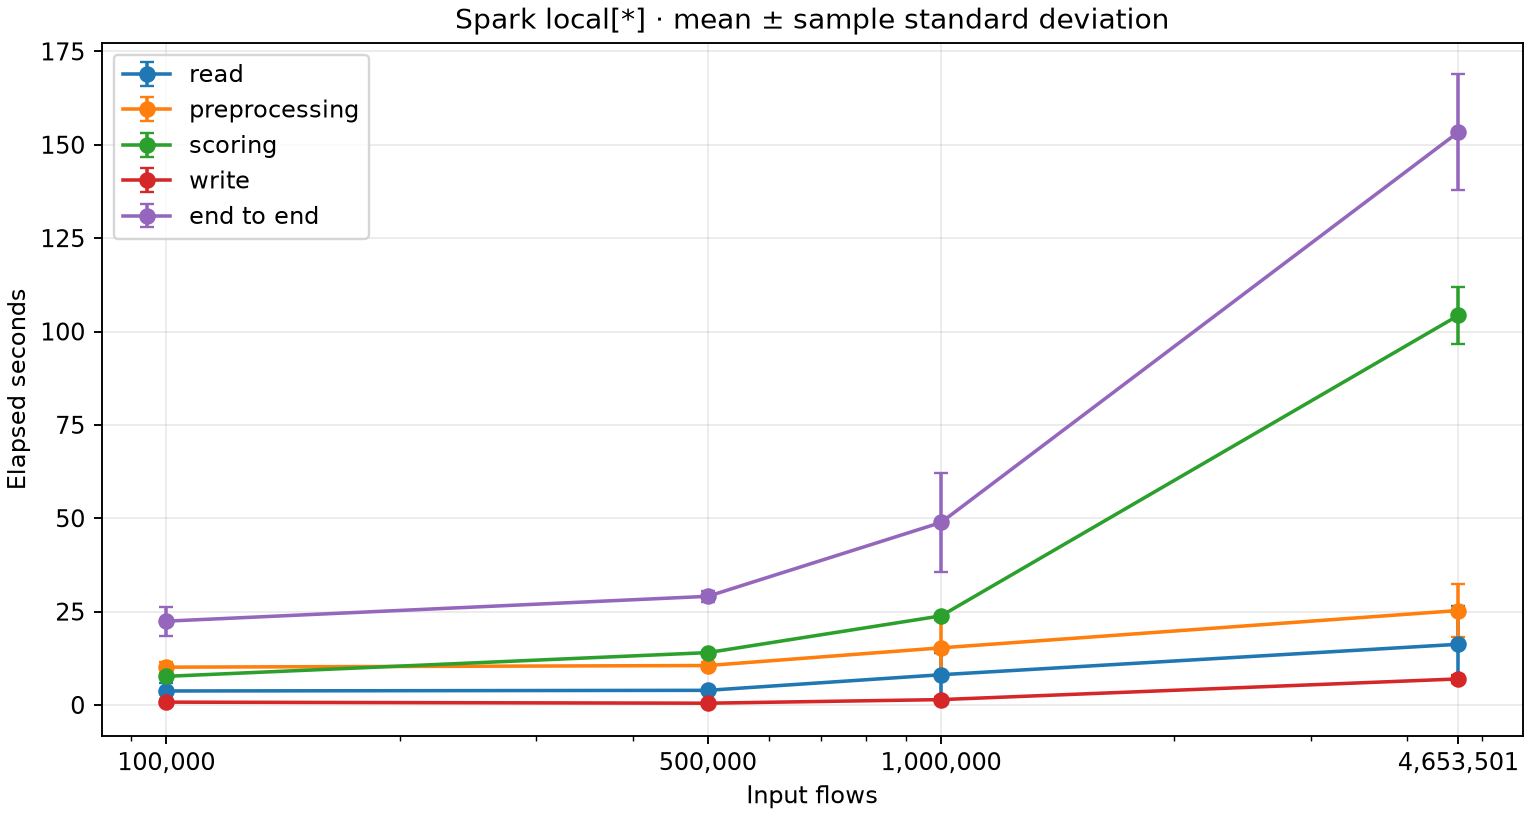

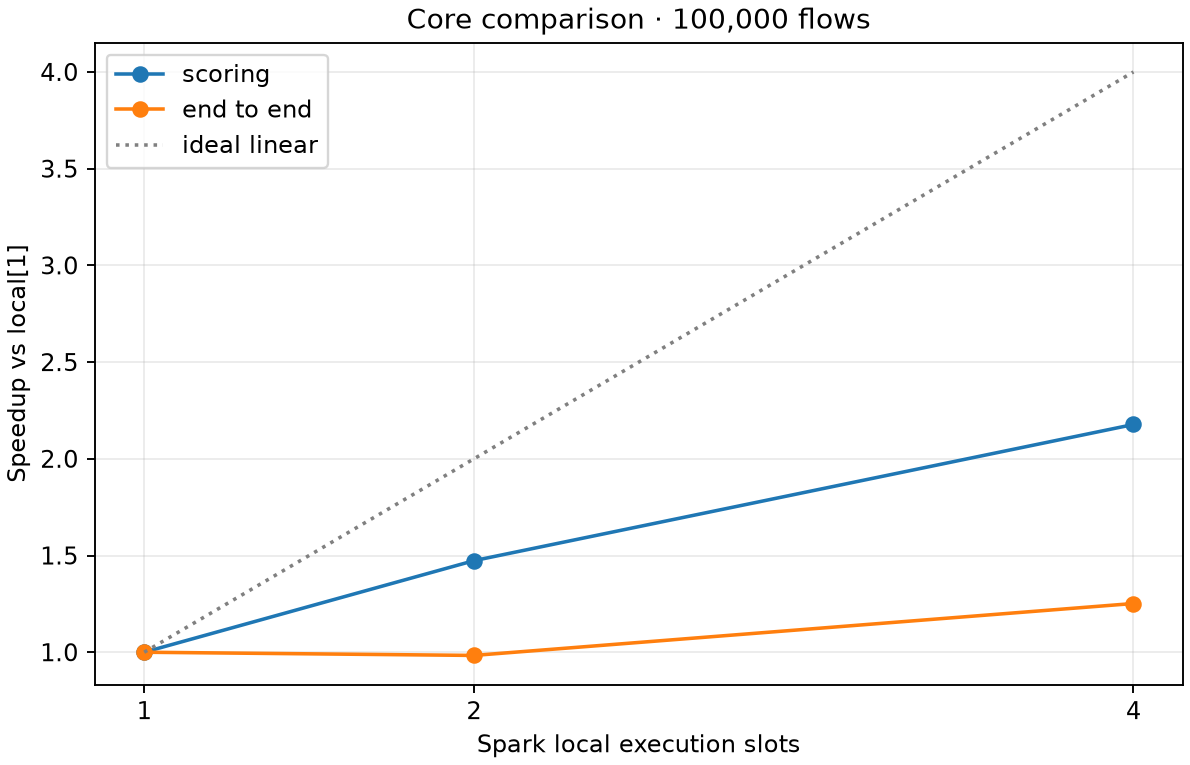

# Spark end-to-end inference benchmark

Đã ghi **21 lượt hoàn tất**. Spark chạy **local trên một máy**.
Spark 3.5.8, Java 11.0.30, Python 3.11.18,
Windows-10-10.0.26300-SP0, 32 CPU logic, driver 4g,
8 shuffle partitions, Arrow tối đa 20000 dòng/batch.
Mỗi Python worker dùng 1 BLAS thread. Các cấu hình master dùng tiến trình JVM riêng.

| Master | Flows | Lượt | Scoring partitions | Read (s) | Prep (s) | Score (s) | Write (s) | E2E (s) | Score flow/s | E2E flow/s |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| local[*] | 100,000 | 3 | 7 | 3.74 ± 2.02 | 10.12 ± 1.46 | 7.66 ± 0.24 | 0.75 ± 0.53 | 22.44 ± 3.92 | 13,064 | 4,551 |
| local[*] | 500,000 | 3 | 16 | 3.92 ± 0.46 | 10.56 ± 1.00 | 14.01 ± 0.31 | 0.47 ± 0.06 | 29.09 ± 1.43 | 35,689 | 17,217 |
| local[*] | 1,000,000 | 3 | 30 | 8.09 ± 5.87 | 15.29 ± 7.42 | 23.85 ± 0.23 | 1.43 ± 0.75 | 48.86 ± 13.21 | 41,935 | 21,370 |
| local[*] | 4,653,501 | 3 | 139 | 16.25 ± 10.23 | 25.28 ± 7.00 | 104.30 ± 7.71 | 6.97 ± 1.10 | 153.38 ± 15.50 | 44,774 | 30,550 |
| local[1] | 100,000 | 3 | 7 | 10.93 ± 8.99 | 33.33 ± 21.83 | 17.98 ± 1.82 | 2.70 ± 1.27 | 65.27 ± 32.87 | 5,600 | 1,936 |
| local[2] | 100,000 | 3 | 7 | 12.36 ± 6.04 | 38.70 ± 2.61 | 12.21 ± 1.02 | 2.78 ± 1.92 | 66.37 ± 9.73 | 8,230 | 1,527 |
| local[4] | 100,000 | 3 | 7 | 11.14 ± 9.35 | 30.59 ± 17.86 | 8.26 ± 0.83 | 1.77 ± 2.39 | 52.14 ± 29.12 | 12,184 | 2,634 |

Thời gian là trung bình ± độ lệch chuẩn mẫu. Throughput là trung bình
của số dòng chia thời gian từng lượt. CSV lưu cả throughput từng pha
và độ lệch chuẩn.

## Phương pháp

- Input nhỏ là tiền tố vật lý cố định của từng ngày, với quota tỷ lệ theo
  số dòng. Full test đọc trực tiếp snapshot 100%. Việc chuẩn bị input,
  nạp model và khởi động Spark diễn ra ngoài phần đo.
- **Read:** Đọc Parquet và materialize toàn bộ cột dùng cho preprocessing
  vào cache Spark `DISK_ONLY` bằng action đếm dòng. **Prep:** Chuẩn hóa nhãn,
  protocol và làm sạch theo pipeline, rồi materialize cột scoring.
- **Score:** Dùng IF, AE, Ensemble và threshold đã lưu. Signed-log và
  z-score chạy bên trong `mapInPandas`. Action đếm từng cột kết quả buộc Spark
  thực thi scoring và cache output. **Write:** Ghi predictions phân vùng
  theo ngày từ output đã materialize. Đọc footer Parquet sau khi dừng đồng
  hồ để kiểm tra số dòng và marker `_SUCCESS`.
- **E2E:** Từ lúc bắt đầu scan đến khi ghi xong, gồm vật liệu hóa cache
  và chi phí chuyển pha. Không gồm training, baseline, tính AUC hay đọc lại.
  Vì có cache đĩa giữa các pha, đây là benchmark cô lập pha và sẽ khác
  runtime của một DAG chạy liền không materialize.
- Cache Spark được giải phóng sau mỗi lượt. `first-size-pass` là lượt đầu
  của kích thước trong cùng JVM sau probe nhỏ. `warm-repeat` là lượt sau
  trên cùng input. Cache hệ điều hành không bị xóa, nên không đo cold disk
  thực sự. Lượt đầu vẫn có thể chịu JIT và khởi động worker.
- So sánh số lõi chỉ thực hiện ở kích thước nhỏ nhất trong kế hoạch.
  Spark slots là giới hạn đồng thời của local master, trong khi máy vẫn
  có thể chạy tiến trình khác. Kết quả phản ánh máy, ổ đĩa và layout file
  này, cùng chi phí Spark khi workload nhỏ.


In [2]:
import pandas as pd
from IPython.display import Image, Markdown, display

display(pd.read_csv(run / "benchmark_summary.csv"))
for name in ("throughput_by_size.png", "processing_time_by_size.png", "speedup_by_cores.png"):
    if (run / name).exists():
        display(Image(filename=str(run / name)))
display(Markdown((run / "benchmark_report.md").read_text(encoding="utf-8")))
